# 23 — Golden vector trên đoạn dữ liệu thật

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Golden vector đã chuẩn bị **không** có nghĩa parity Python/C hay triển khai ESP32 đã được kiểm chứng. Trạng thái: `PYTHON_REFERENCE_READY` · `C_PARITY_PENDING`.

**Mục tiêu.** Trích các đoạn tất định từ dữ liệu processed Hohai, Seafar, Southampton; tính golden bằng extractor production; đối chiếu với feature table đã có để bắt lỗi cắt đoạn/ranh giới. Đoạn trích chỉ nằm trong **một** segment, không dùng mẫu tương lai. Dữ liệu và golden real **không** được đưa lên Git (`ml/data/parity/` bị gitignore).

In [1]:
from pathlib import Path
import json, sys, hashlib, math, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/parity/golden.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/parity/golden.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from ml.parity.golden import REAL_ROOT, MANIFEST, read_inputs
from ml.parity.contract import FEATURE_ORDER
from ml.parity import compare
manifest = json.loads((REPO_ROOT / MANIFEST).read_text(encoding="utf-8"))
REAL_OK = (REPO_ROOT / REAL_ROOT / "expected_features.csv").is_file()
print("Golden real có trên máy này:", REAL_OK)
if REAL_OK:
    expected, cases = compare.load_golden(REPO_ROOT, "real")
    print("Case:", len(cases), "| endpoint:", manifest["suites"]["real"]["endpoints"], "| bản ghi:", len(expected))

Golden real có trên máy này: True
Case: 5 | endpoint: 95 | bản ghi: 2185


## 1. Quy tắc chọn đoạn (tất định)

| Case | Quy tắc |
|---|---|
| Hohai max/min | session có median `roll_std_60` lớn nhất/nhỏ nhất trong feature table; đoạn bắt đầu tại mẫu 3000 |
| Seafar giữa | segment dài nhất; đoạn ở giữa, bắt đầu tại bội số 100 |
| Seafar max | cửa sổ có `roll_std_60` lớn nhất; đoạn kết thúc tại endpoint đó |
| Southampton | Run 14 (run duy nhất đủ 180 s); đoạn kết thúc tại endpoint lưới cuối |

Mẫu bắt đầu là bội số 100 nên lưới endpoint của đoạn trùng lưới endpoint của segment (endpoint = chỉ số 600 + 100·j).

In [2]:
if REAL_OK:
    catalog = pd.DataFrame([{k: c[k] for k in ("case_id", "dataset_source", "session_id", "segment_id", "source_start_index", "n_samples",
                                               "endpoint_count", "time_first_s", "time_last_s", "dropped_timestamps")} for c in cases.values()])
    display(catalog)
    display(pd.DataFrame({c["case_id"]: c["source_provenance"] for c in cases.values()}).T[["source_class", "original_sampling_hz", "preprocessing_version", "filter"]])

,case_id,dataset_source,session_id,segment_id,source_start_index,n_samples,endpoint_count,time_first_s,time_last_s,dropped_timestamps
0,REAL_hohai_max_roll_std,hohai,Berth_D_T9_Type_A,segment_000,3000,2401,19,302.0,542.0,0
1,REAL_hohai_min_roll_std,hohai,Berth_D_T1_Type_A,segment_000,3000,2401,19,302.0,542.0,0
2,REAL_seafar_longest_segment_middle,seafar,seafar_session_001,segment_002,29900,2401,19,5628.8,5868.8,0
3,REAL_seafar_max_roll_std,seafar,seafar_session_001,segment_001,19400,2401,19,1941.0,2181.0,0
4,REAL_southampton_run14_end,southampton,southampton_run_14,segment_000,2700,2401,19,272.0,512.0,0


,source_class,original_sampling_hz,preprocessing_version,filter
REAL_hohai_max_roll_std,SENSOR,50.0,0.1.0,"{'applied': True, 'channels_filtered': ['sway_m', 'surge_m', 'heave_m', 'roll_deg', 'pitch_deg', 'yaw_deg'], 'cutoff..."
REAL_hohai_min_roll_std,SENSOR,50.0,0.1.0,"{'applied': True, 'channels_filtered': ['sway_m', 'surge_m', 'heave_m', 'roll_deg', 'pitch_deg', 'yaw_deg'], 'cutoff..."
REAL_seafar_longest_segment_middle,SENSOR,10.00001,0.1.0,"{'applied': False, 'channels_filtered': [], 'cutoff_hz': None, 'initialization': 'steady-state at first sample', 'me..."
REAL_seafar_max_roll_std,SENSOR,10.00001,0.1.0,"{'applied': False, 'channels_filtered': [], 'cutoff_hz': None, 'initialization': 'steady-state at first sample', 'me..."
REAL_southampton_run14_end,SENSOR,50.0,0.1.0,"{'applied': True, 'channels_filtered': ['heave_m', 'roll_deg', 'pitch_deg', 'yaw_deg', 'accel_x_m_s2', 'accel_y_m_s2..."


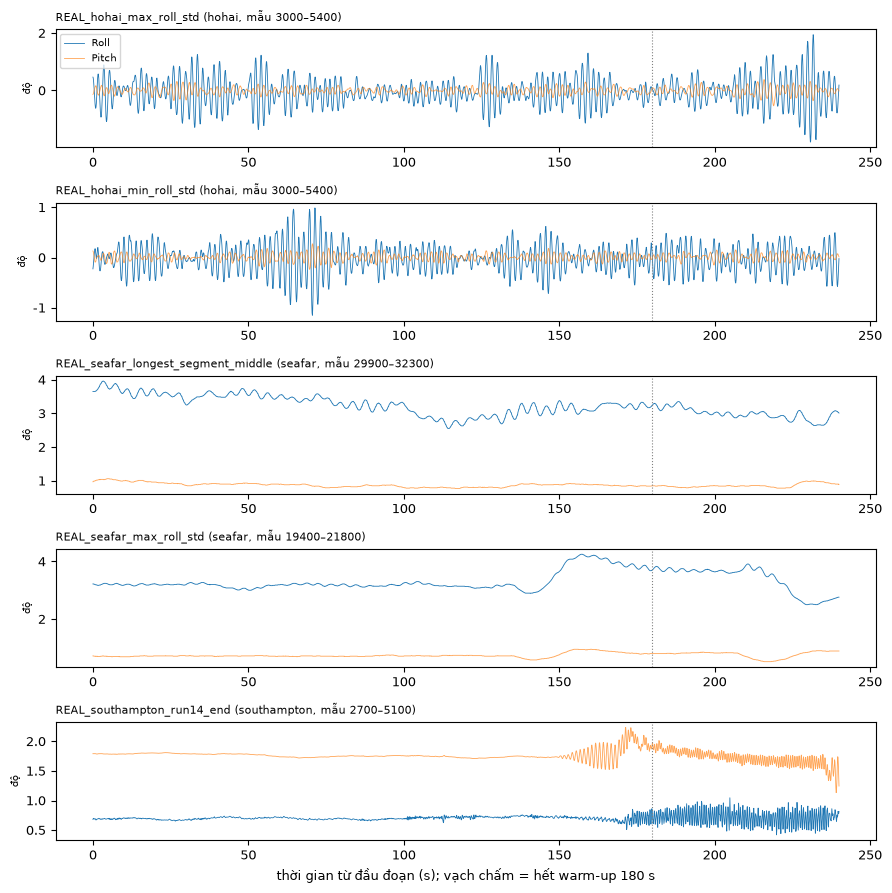

In [3]:
if REAL_OK:
    fig, axes = plt.subplots(len(cases), 1, figsize=(9, 1.8 * len(cases)))
    for ax, c in zip(axes, cases.values()):
        d = read_inputs(REPO_ROOT / c["input_file"])
        rel = d.time_seconds - d.time_seconds.iloc[0]
        ax.plot(rel, d.roll_deg, lw=0.6, label="Roll"); ax.plot(rel, d.pitch_deg, lw=0.6, alpha=0.7, label="Pitch")
        ax.axvline(180, color="grey", ls=":", lw=0.8)
        ax.set_title(f"{c['case_id']} ({c['dataset_source']}, mẫu {c['source_start_index']}–{c['source_start_index'] + c['n_samples'] - 1})", fontsize=8, loc="left")
        ax.set_ylabel("độ", fontsize=7)
    axes[0].legend(fontsize=7); axes[-1].set_xlabel("thời gian từ đầu đoạn (s); vạch chấm = hết warm-up 180 s")
    plt.tight_layout(); plt.show()

## 2. Golden tại endpoint cuối và đối chiếu feature table

Vì Roll/Pitch processed đã lưu dạng float32, việc làm tròn float32 của golden không làm đổi giá trị; chênh lệch kỳ vọng với feature table là **0 tuyệt đối**. Feature 180 s ở các endpoint đầu đoạn (< 180 s lịch sử trong đoạn) là WARM-UP theo thiết kế và không được so.

In [4]:
if REAL_OK:
    last = expected.loc[expected.endpoint_index == expected.groupby("case_id").endpoint_index.transform("max")]
    wide = last.pivot(index="case_id", columns="feature_index", values="value"); wide.columns = list(FEATURE_ORDER)
    display(wide.T.map(lambda v: "" if v is None else f"{v:.5g}"))
    display(pd.DataFrame(manifest["real_cross_check"]["cases"]))
    print("Đối chiếu đạt:", manifest["real_cross_check"]["passed"])
    display(expected.groupby(["case_id", "status"]).size().unstack(fill_value=0))

case_id,REAL_hohai_max_roll_std,REAL_hohai_min_roll_std,REAL_seafar_longest_segment_middle,REAL_seafar_max_roll_std,REAL_southampton_run14_end
roll_rms_60,0.57654,0.26153,2.9871,3.4035,0.72242
roll_std_60,0.57527,0.25857,0.16619,0.4696,0.11991
roll_mean_60,-0.03818,-0.039245,2.9825,3.3709,0.7124
roll_peak_to_peak_60,3.735,1.0707,0.71,1.41,0.62628
roll_abs_p95_60,1.1961,0.4739,3.28,3.81,0.89622
roll_abs_max_60,1.9404,0.57549,3.35,3.91,1.046
roll_iqr_60,0.70125,0.39771,0.1725,0.8725,0.18856
roll_diff_rms_60,0.1984,0.09167,0.01067,0.009026,0.10944
roll_mean_180,-0.058763,-0.032948,3.0808,3.3694,0.70538
roll_median_180,-0.074004,-0.02566,3.08,3.21,0.70439


,case_id,max_abs_difference,validity_mismatch,values_compared
0,REAL_hohai_max_roll_std,0.0,0,293
1,REAL_hohai_min_roll_std,0.0,0,293
2,REAL_seafar_longest_segment_middle,0.0,0,293
3,REAL_seafar_max_roll_std,0.0,0,293
4,REAL_southampton_run14_end,0.0,0,293


Đối chiếu đạt: True


status,INSUFFICIENT_WINDOW,VALID
case_id,,
REAL_hohai_max_roll_std,144,293
REAL_hohai_min_roll_std,144,293
REAL_seafar_longest_segment_middle,144,293
REAL_seafar_max_roll_std,144,293
REAL_southampton_run14_end,144,293


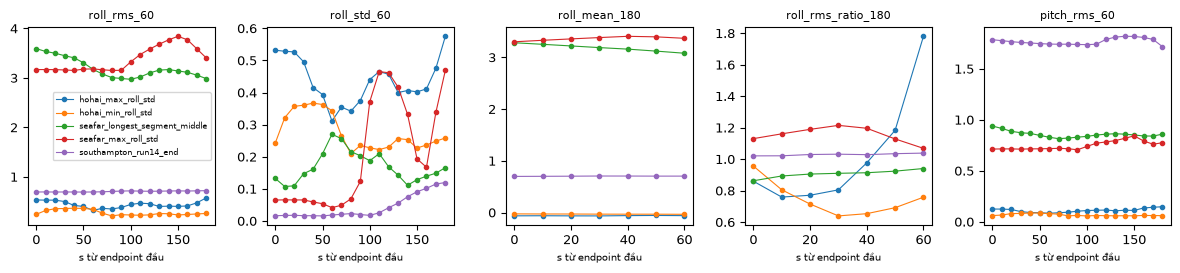

In [5]:
if REAL_OK:
    feats = ["roll_rms_60", "roll_std_60", "roll_mean_180", "roll_rms_ratio_180", "pitch_rms_60"]
    fig, axes = plt.subplots(1, len(feats), figsize=(12, 2.8))
    for ax, f in zip(axes, feats):
        for cid in cases:
            sub = expected.loc[(expected.case_id == cid) & (expected.feature_name == f) & (expected.status == "VALID")]
            ax.plot(sub.endpoint_time_seconds - sub.endpoint_time_seconds.min(), sub.value.astype(float), marker=".", lw=0.8, label=cid.replace("REAL_", ""))
        ax.set_title(f, fontsize=8); ax.set_xlabel("s từ endpoint đầu", fontsize=7)
    axes[0].legend(fontsize=6); plt.tight_layout(); plt.show()

## Diễn giải

- Năm đoạn phủ cả ba dataset và hai thái cực biên độ (Hohai max/min, Seafar max), thêm pha tăng biên độ cuối Run 14 của Southampton.
- Golden real trùng tuyệt đối với feature table đã có → cách trích đoạn, lưới endpoint và ranh giới cửa sổ là đúng.
- Fixture real giúp M1 kiểm tra trên phân phối giá trị thật (offset lượng tử 0,01° của Seafar, chu kỳ ngắn của Hohai), bổ sung cho tín hiệu toán học.

## Hạn chế

- Năm đoạn × 19 endpoint là mẫu đại diện, không phải đánh giá thống kê.
- Golden real chỉ tồn tại trên máy có dữ liệu processed; M1 cần chạy `python -m ml.parity.golden --suite real` hoặc nhận file từ M2 qua kênh riêng.
- Roll/Pitch của dataset đến từ hệ đo khác ESP32 (xem `esp32_feature_compatibility.md`); parity trên đoạn này vẫn chỉ là Level 2.

## Ghi chú vấn đáp

- *Vì sao start là bội số 100?* Để endpoint của đoạn trích trùng endpoint của segment gốc, cho phép so trực tiếp với feature table.
- *Có rò rỉ tương lai không?* Không: feature tại endpoint chỉ dùng mẫu có $t\le t_e$; đoạn trích không vượt ranh giới segment.
- *Tại sao không đưa dữ liệu thật lên Git?* Dữ liệu nguồn là dataset cục bộ/có giấy phép riêng; chỉ fixture toán học nhỏ được theo dõi.